# IND320 Part 4 — Machine learning: forecasts, exchange rates and a refactored app

This notebook continues Parts 1–3. Part 4 adds exchange rates from **Norges Bank**, investigates **time zones**
in the four data sources, builds a **weekly weather history** for every reservoir area, studies the **sliding window
correlation** between weather and reservoirs, and develops **forecasts of the fill level** with the River framework.
The Streamlit app is refactored at the same time (Plotly charts, grouped menu, map, new pages).

**Contents**

1. Setup
2. Sketch of the new app structure
3. Exchange rates from Norges Bank
4. Time zones in NVE, ENTSO-E, Open-Meteo and Norges Bank
5. Weekly weather history for all areas (Open-Meteo → MongoDB)
6. Sliding window correlation: weather against reservoirs
7. Forecasting the fill level with River (SNARIMAX and lag regression)
8. AI usage
9. Work log

## Project links

- Public GitHub repository: https://github.com/yaksh-git/ind320-dashboard-basics-yaksh-git
  (Part 4 is developed on the branch `ind320-part4` and merged into `main` after peer review 3 and feedback 3)
- Streamlit app: https://ind320-dashboard-basics-yaksh-git.streamlit.app/
- Screencast (Part 4): https://github.com/yaksh-git/ind320-dashboard-basics-yaksh-git/blob/main/docs/part_4/screencast_part4.mp4
- The AI-usage statement and the work log are in sections 8 and 9 at the end.

## 1. Setup

The notebook lives in `notebooks/` and uses the project's Python 3.12 environment (`notebooks/requirements.txt`).
Following the advice from peer review 3, the first code cell contains **only the imports**; the second cell sets up
paths, the plot style and the connection settings. Secrets (the MongoDB connection string) are read from the
Git-ignored file `.streamlit/secrets.toml`; only the section names are printed, never the values.

In [1]:
# Imports only (peer review 3: imports in the first cell, setup in the next one)
import inspect
import json
import sys
import time
import tomllib
from datetime import date
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from IPython.display import Image, display
from pymongo import ASCENDING, MongoClient, UpdateOne
from river import linear_model, optim, preprocessing, time_series

In [2]:
# Setup: paths, plot style, secrets, URLs and the app's shared code (src/utils/forecast.py and locations.py)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()  # Jupyter starts in notebooks/
REGION_DIR = ROOT / 'data' / 'regions'            # small map files that the app also uses (in Git)
CACHE_DIR = ROOT / 'data' / 'cache'               # large downloads (Git-ignored, re-created by this notebook)
DAILY_CACHE = CACHE_DIR / 'weather_daily_kmeans12'   # daily weather at 12 weighted cells per area
DAILY_CACHE.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')

with open(ROOT / '.streamlit' / 'secrets.toml', 'rb') as file:
    secrets = tomllib.load(file)
print('Secret sections found:', ', '.join(secrets))  # names only, never the values

NVE_URL = 'https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData'
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'
NB_URL = 'https://data.norges-bank.no/api/data/EXR/B.{currencies}.NOK.SP'

# The forecasting and location code is shared with the app, so the notebook tests exactly the code the app runs.
sys.path.insert(0, str(ROOT))
from src.utils import forecast as fc  # noqa: E402 (needs the path above)
from src.utils.locations import representative_cells, weighted_area_mean  # noqa: E402
print('pandas', pd.__version__, '| River model classes:', time_series.SNARIMAX.__name__)

Secret sections found: mongo, entsoe


pandas 2.3.3 | River model classes: SNARIMAX


## 2. Sketch of the new app structure

Before changing the code I drew the new structure on paper (the assignment asks for a sketch before refactoring).
The sketch shows an A4 page laid out like the app: the menu with its groups on the left, and the new **Map** page on
the right. The circles mark the three new pages in Part 4.

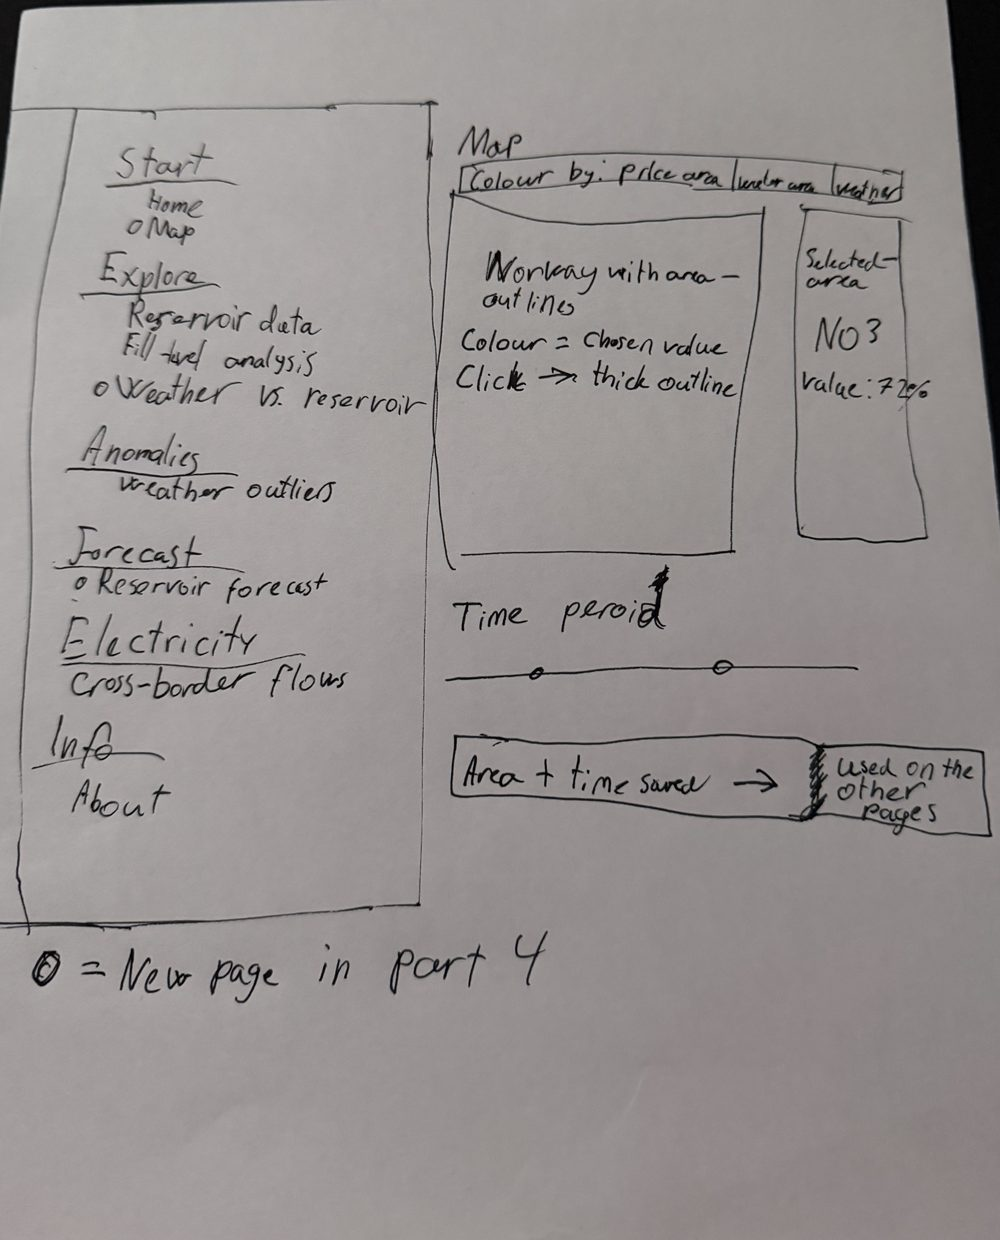

In [3]:
# Show the hand-drawn sketch (photo, cropped to the paper)
display(Image(filename=str(ROOT / 'docs' / 'part_4' / 'sketch_app_structure.jpg'), width=620))

**Decisions shown in the sketch**

- **Grouping by type of task.** Parts 2–3 grouped the menu by data source. The new pages combine sources (the forecast
  uses NVE, Open-Meteo and Norges Bank), so the menu is now grouped by task: **Start** (Home, Map), **Explore**
  (Reservoir data, Fill-level analysis, Weather vs. reservoir), **Anomalies** (Weather outliers), **Forecast**
  (Reservoir forecast), **Electricity** (Cross-border flows) and **Info** (About). Each group has its own colour, used in the
  page header and on the active menu entry, so the user can see which group is active. The Home page has one card per
  group that leads to its main page.
- **The LineChartColumn page.** The old *Data table* page (with `LineChartColumn`) and *Data plot* page showed the same
  data with the same controls, so they are joined into one page, **Reservoir data**, with the tabs *Table* and *Plot*.
- **Global and local selections.** The area and the time period are global: a click on the map (thick outline) stores
  the area in `st.session_state`, and the analysis pages open with it; the map's time period is also the training
  period of the forecast. Choices that only make sense on one page stay local (year on Weather outliers, lag and window
  on Weather vs. reservoir, model parameters on Forecast).

## 3. Exchange rates from Norges Bank

Norges Bank publishes its exchange rates through an open SDMX REST API (no key). The data set `EXR` is addressed by
a key with four parts: frequency `B` (business days), base currency (`EUR+USD`), quote currency `NOK` and the type
`SP` (spot). With `format=csv` the answer is a semicolon-separated table with one row per currency and day.
The app uses the same function (`src/utils/currency.py`), with caching, for the exchange rate as an exogenous
variable in the forecast.

In [4]:
# Function: download daily EUR/NOK and USD/NOK between two dates from Norges Bank (one column per currency)
def download_exchange_rates(start: str, end: str, currencies: tuple[str, ...] = ('EUR', 'USD')) -> pd.DataFrame:
    """Daily rates in NOK per unit of each currency, indexed by date (business days only)."""
    url = NB_URL.format(currencies='+'.join(currencies))
    params = {'format': 'csv', 'startPeriod': start, 'endPeriod': end, 'locale': 'en'}
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()  # stop with a clear error on HTTP 4xx/5xx
    rows = pd.read_csv(StringIO(response.text), sep=';')
    rows['TIME_PERIOD'] = pd.to_datetime(rows['TIME_PERIOD'], format='%Y-%m-%d')
    # From long (one row per currency and day) to wide (one column per currency).
    rates = rows.pivot(index='TIME_PERIOD', columns='BASE_CUR', values='OBS_VALUE')
    return rates.rename_axis(index='date', columns=None)

In [5]:
# Test: download from 2016 to today and check that the result looks like exchange rates
rates = download_exchange_rates('2016-01-01', f'{date.today():%Y-%m-%d}')
assert list(rates.columns) == ['EUR', 'USD'], 'one column per currency'
assert rates.index.dayofweek.max() <= 4, 'business days only (Monday = 0, Friday = 4)'
assert rates.notna().all().all(), 'no missing values'
assert rates['EUR'].between(8, 14).all() and rates['USD'].between(6, 13).all(), 'plausible NOK rates'
print(f'{len(rates):,} business days from {rates.index[0]:%d %b %Y} to {rates.index[-1]:%d %b %Y}')
display(rates.tail(3))
display(rates.describe().round(3))

2,740 business days from 04 Jan 2016 to 19 Nov 2026


,EUR,USD
date,,
2026-11-17,10.5755,9.6237
2026-11-18,10.6045,9.6686
2026-11-19,10.6475,9.6866


,EUR,USD
count,2740.000,2740.000
mean,10.433,9.312
std,0.904,0.980
min,8.807,7.658
25%,9.645,8.489
50%,10.259,9.098
75%,11.339,10.162
max,12.316,11.482


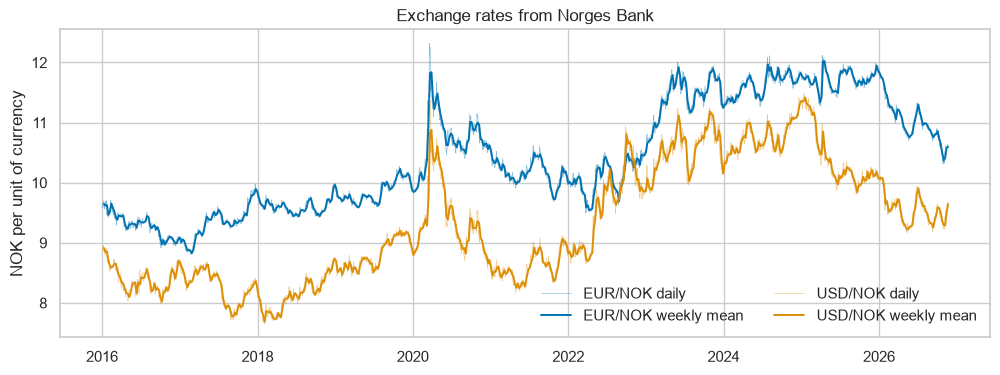

In [6]:
# Plot: daily rates and weekly means (both in NOK per unit of currency, so one y-axis is correct)
weekly_rates = rates.resample('W-SUN').mean()  # weeks that end on Sunday, like NVE's weeks
fig, ax = plt.subplots(figsize=(12, 4))
for currency, colour in [('EUR', '#0173B2'), ('USD', '#DE8F05')]:
    ax.plot(rates.index, rates[currency], color=colour, linewidth=0.5, alpha=0.45, label=f'{currency}/NOK daily')
    ax.plot(weekly_rates.index, weekly_rates[currency], color=colour, linewidth=1.4, label=f'{currency}/NOK weekly mean')
ax.set(title='Exchange rates from Norges Bank', xlabel='', ylabel='NOK per unit of currency')
ax.legend(ncol=2, frameon=False)
plt.show()

**Findings.** The function returns 2,736 business days from 4 January 2016, with no weekends and no missing values. The krone
weakened over the period: the yearly mean of EUR/NOK rose from 9.3 (2016) to 11.7 (2025), and USD/NOK from 8.4 to
10.4. The highest EUR/NOK, 12.32, was on 19 March 2020, at the start of the COVID-19 pandemic, when the krone fell
together with the oil price; USD/NOK peaked at 11.48 in January 2025. In 2026 the krone has strengthened again
(EUR/NOK about 11.0 on average). The weekly means remove the day-to-day noise and lie on the same weeks as NVE's data,
which is how the forecast uses them.

## 4. Time zones in NVE, ENTSO-E, Open-Meteo and Norges Bank

The four sources describe time in different ways. The checks below look at the raw data of each source; the summary
table at the end gives the solution used in the notebook and the app.

In [7]:
# NVE: dato_Id is a plain date without time or time zone; check its weekday and the ISO week fields
nve = pd.DataFrame(requests.get(NVE_URL, headers={'Accept': 'application/json'}, timeout=60).json())
nve_dates = pd.to_datetime(nve['dato_Id'], format='%Y-%m-%d')
nve['date'] = nve_dates  # used again in sections 6 and 7
iso = nve_dates.dt.isocalendar()
print('Raw values (newest row): dato_Id =', nve['dato_Id'].iloc[-1],
      '| neste_Publiseringsdato =', nve['neste_Publiseringsdato'].iloc[-1])
print('Weekdays of dato_Id:', nve_dates.dt.day_name().value_counts().to_dict())
assert (iso['week'].to_numpy() == nve['iso_uke'].to_numpy()).all(), 'iso_uke is the ISO week of dato_Id'
assert (iso['year'].to_numpy() == nve['iso_aar'].to_numpy()).all(), 'iso_aar is the ISO year of dato_Id'
print('iso_aar and iso_uke agree with dato_Id in all', f'{len(nve):,}', 'rows')

Raw values (newest row): dato_Id = 2026-11-08 | neste_Publiseringsdato = 2026-11-18T13:00:00
Weekdays of dato_Id: {'Sunday': 14967}
iso_aar and iso_uke agree with dato_Id in all 14,967 rows


In [8]:
# ENTSO-E: the Part 2 cache keeps the API's UTC times; count 15-minute values per Norwegian day around the DST changes
flows = pd.read_parquet(CACHE_DIR / 'entsoe_physical_flows_2024_2025.parquet', columns=['time', 'link', 'direction'])
nl = flows.loc[(flows['link'] == 'NO2-DE') & (flows['direction'] == 'import'), 'time']  # NO2-DE: 15-minute values only
print('Stored time zone:', nl.dt.tz, '| first value:', nl.min(), '=', nl.min().tz_convert('Europe/Oslo'), 'in Oslo')
local_days = nl.dt.tz_convert('Europe/Oslo').dt.date
per_day = local_days.value_counts()
for day in [date(2024, 3, 30), date(2024, 3, 31), date(2024, 10, 27)]:
    print(f'{day}: {per_day[day]} quarter-hours ({per_day[day] / 4:g} hours) in Norwegian local time')

Stored time zone: UTC | first value: 2023-12-31 23:00:00+00:00 = 2024-01-01 00:00:00+01:00 in Oslo
2024-03-30: 96 quarter-hours (24 hours) in Norwegian local time
2024-03-31: 92 quarter-hours (23 hours) in Norwegian local time
2024-10-27: 100 quarter-hours (25 hours) in Norwegian local time


In [9]:
# Open-Meteo: the same location and days with the default timezone (GMT) and with timezone=Europe/Oslo
answers = {}
for zone in ['GMT', 'Europe/Oslo']:
    params = {'latitude': 63.5, 'longitude': 10.5, 'start_date': '2024-01-10', 'end_date': '2024-01-11',
              'daily': 'precipitation_sum', 'hourly': 'temperature_2m', 'models': 'era5', 'timezone': zone}
    answers[zone] = requests.get(ARCHIVE_URL, params=params, timeout=60).json()
for zone, answer in answers.items():
    print(f"{zone:12} utc_offset_seconds={answer['utc_offset_seconds']:5} first hour='{answer['hourly']['time'][0]}' "
          f"daily precipitation={answer['daily']['precipitation_sum']} mm")

GMT          utc_offset_seconds=    0 first hour='2024-01-10T00:00' daily precipitation=[6.3, 8.5] mm
Europe/Oslo  utc_offset_seconds= 3600 first hour='2024-01-10T00:00' daily precipitation=[5.8, 8.9] mm


In [10]:
# Norges Bank: rates exist only on business days, and the raw CSV says when they are fixed
raw = pd.read_csv(StringIO(requests.get(NB_URL.format(currencies='EUR'), timeout=60,
                  params={'format': 'csv', 'startPeriod': '2025-12-20', 'endPeriod': '2026-01-05',
                          'locale': 'en'}).text), sep=';')
print('Collection indicator:', raw['Collection Indicator'].iloc[0])
print('Dates around Christmas 2025:', ', '.join(raw['TIME_PERIOD']))
print('Weekdays in the whole download:', rates.index.day_name().value_counts().to_dict())

Collection indicator: ECB concertation time 14:15 CET
Dates around Christmas 2025: 2025-12-22, 2025-12-23, 2025-12-29, 2025-12-30, 2025-12-31, 2026-01-02, 2026-01-05
Weekdays in the whole download: {'Tuesday': 559, 'Wednesday': 558, 'Friday': 548, 'Thursday': 539, 'Monday': 536}


**Findings and solution**

| Source | How time is given | Problem | Solution used |
|---|---|---|---|
| NVE (Magasinstatistikk) | `dato_Id` is a date without time (always a **Sunday**, the end of the ISO week); `iso_aar`/`iso_uke` agree with it; `neste_Publiseringsdato` has a time but no zone (Norwegian local time) | none for weekly data, but other data must be put on the same weeks | All weekly series use weeks that end on Sunday (`resample('W-SUN')`), labelled by that Sunday |
| ENTSO-E | UTC timestamps (`…Z`), 15- or 60-minute resolution | a Norwegian day has 23 or 25 hours at the daylight-saving changes; a UTC day ends at 01:00/02:00 in Norway | Store in UTC; convert to `Europe/Oslo` before grouping by day, month or year (done in Part 2) |
| Open-Meteo | `timezone` parameter, **GMT by default**; times are local strings without an offset; `utc_offset_seconds` gives the offset | daily sums depend on the zone (5.8 mm in Oslo time vs 6.3 mm in GMT above) | Hourly data in UTC (Part 3); daily data with `timezone=Europe/Oslo`, so a day is a Norwegian day |
| Norges Bank | dates only, **business days only**, fixed at about 14:15 CET (ECB concertation) | no values on weekends and holidays; the fixing time is one moment of the day | Weekly mean of the business days in each NVE week; weeks without a rate are filled with the previous week |

After these steps every series is on the same weekly grid as NVE: one value per ISO week, labelled by the Sunday that
ends it, with days counted in Norwegian time. The remaining difference is that ENTSO-E and hourly weather are measured
in UTC hours, but this does not matter after summing to weeks (at most one or two hours move between neighbouring weeks).

## 5. Weekly weather history for all areas (Open-Meteo → MongoDB)

The map, the correlation page and the forecast need **many years of weather for every area**. Part 3 downloaded one
year of hourly data at 20 locations when the page needed it; that does not scale to ten years and eight areas.
Open-Meteo's free plan allows 10,000 calls per day, 5,000 per hour and 600 per minute, and a request counts as one
call per location for each started 14 days (with at most 10 variables). Ten years at one location therefore cost
about 280 calls.

The design is therefore:

- **12 representative locations per area.** The teacher's feedback on Part 3 asked for more of the 1000 random
  locations, so that the area means are more representative. All of them is impossible: they fall in about 2,100
  different ERA5 grid cells (0.25°) in the eight areas, which would cost about 600,000 calls. Points in the same cell get
  identical weather, so the mean of the 1000 points is a mean over the cells weighted by the number of points in each.
  To get close to it with few downloads, the 1000 points are grouped into 12 compact clusters (k-means); each cluster
  is represented by its most common ERA5 cell, **weighted by its share of the points** (`src/utils/locations.py`, also
  used by the app). Section 5.4 tests this against the mean of all 1000 points.
- **Daily** values (mean temperature, precipitation sum, snowfall sum) with `timezone=Europe/Oslo`, from 2016 onwards.
- Each area–year is **cached** as a Parquet file and the downloads are **throttled** to 4,500 calls per hour. The 8 areas
  cost about 27,000 calls, so the download was spread over three days. (A first version with 6 random locations per
  area, used before the teacher's feedback, cost 13,600 calls.)
- The daily values are averaged over the locations with the weights and aggregated to **ISO weeks that end on Sunday**
  (as NVE).
- **Norway (NO 0)** is the land-area-weighted mean of the five price areas, which together cover the country.
- The weekly table (about 5,000 rows) is stored in **MongoDB**; the app reads it from there.

### 5.1 Locations (from CSV to GeoJSON)

Peer review 3 pointed out the CSV file with the random locations from Part 3. The locations are now stored as GeoJSON
(`data/regions/sample_points.geojson`), with one `MultiPoint` per area, which is also the map format the assignment asks
for. The CSV is no longer in the repository; the cell converts it once if it is still on disk.

In [11]:
# Random locations from Part 3: convert the CSV to GeoJSON once, then read the GeoJSON (one MultiPoint per area)
points_csv, points_file = REGION_DIR / 'sample_points.csv', REGION_DIR / 'sample_points.geojson'
if not points_file.exists():
    old = pd.read_csv(points_csv)
    features = [{'type': 'Feature', 'properties': {'area_type': kind, 'area_number': int(number)},
                 'geometry': {'type': 'MultiPoint', 'coordinates': group[['lon', 'lat']].round(4).values.tolist()}}
                for (kind, number), group in old.groupby(['area_type', 'area_number'], sort=False)]
    points_file.write_text(json.dumps({'type': 'FeatureCollection', 'features': features}, separators=(',', ':')))

point_features = json.loads(points_file.read_text(encoding='utf-8'))['features']
points = pd.DataFrame([{'area_type': f['properties']['area_type'], 'area_number': f['properties']['area_number'],
                        'lon': lon, 'lat': lat}
                       for f in point_features for lon, lat in f['geometry']['coordinates']])
print(f'{points_file.name}: {points_file.stat().st_size / 1000:.0f} kB,', len(points), 'points')
print(points.groupby(['area_type', 'area_number']).size().to_dict())

sample_points.geojson: 156 kB, 9000 points
{('EL', 1): 1000, ('EL', 2): 1000, ('EL', 3): 1000, ('EL', 4): 1000, ('EL', 5): 1000, ('NO', 0): 1000, ('VASS', 1): 1000, ('VASS', 2): 1000, ('VASS', 3): 1000}


### 5.2 Download daily weather per area

In [12]:
# Functions: download daily ERA5 values for an area's representative cells and cache each area-year as Parquet
DAILY_VARIABLES = ['temperature_2m_mean', 'precipitation_sum', 'snowfall_sum']
N_LOCATIONS = 12  # representative cells per area (tested in section 5.4)
FIRST_DAY, LAST_DAY = pd.Timestamp('2016-01-01'), pd.Timestamp('2026-11-08')  # last NVE week when this was written
CALLS_PER_HOUR = 4500  # below the free limit of 5,000 calls per hour


def area_points(points: pd.DataFrame, area_type: str, area_number: int) -> pd.DataFrame:
    """The 1000 random locations of one area (columns lon, lat)."""
    return points.loc[(points['area_type'] == area_type) & (points['area_number'] == area_number), ['lon', 'lat']]


def download_daily(locations: pd.DataFrame, start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    """One Open-Meteo request for all locations; daily values in Norwegian days, one row per location and day."""
    params = {'latitude': ','.join(map(str, locations['lat'])), 'longitude': ','.join(map(str, locations['lon'])),
              'start_date': f'{start:%Y-%m-%d}', 'end_date': f'{end:%Y-%m-%d}', 'daily': ','.join(DAILY_VARIABLES),
              'models': 'era5', 'timezone': 'Europe/Oslo'}
    while True:
        response = requests.get(ARCHIVE_URL, params=params, timeout=300)
        if response.status_code != 429:
            break
        print('Rate limit:', response.json().get('reason'), '- waiting 15 minutes')  # HTTP 429 = too many calls
        time.sleep(15 * 60)
    response.raise_for_status()
    answer = response.json()
    answer = answer if isinstance(answer, list) else [answer]  # one location gives one object, not a list
    return pd.concat([pd.DataFrame(item['daily']).assign(location=i) for i, item in enumerate(answer)],
                     ignore_index=True)


def area_daily_weather(points: pd.DataFrame, area_type: str, area_number: int) -> pd.DataFrame:
    """Daily weather of one area (weighted mean of its cells), downloaded year by year or read from the cache."""
    cells = representative_cells(area_points(points, area_type, area_number), N_LOCATIONS)
    frames = []
    for year in range(FIRST_DAY.year, LAST_DAY.year + 1):
        target = DAILY_CACHE / f'{area_type}{area_number}_{year}.parquet'
        if not target.exists():
            start, end = max(FIRST_DAY, pd.Timestamp(f'{year}-01-01')), min(LAST_DAY, pd.Timestamp(f'{year}-12-31'))
            download_daily(cells, start, end).to_parquet(target)
            calls = len(cells) * ((end - start).days + 1) / 14
            time.sleep(calls / CALLS_PER_HOUR * 3600)  # stay below the hourly limit
        frames.append(pd.read_parquet(target))
    daily = pd.concat(frames, ignore_index=True)
    daily['time'] = pd.to_datetime(daily['time'], format='%Y-%m-%d')
    return weighted_area_mean(daily, cells['weight'], 'time', DAILY_VARIABLES)  # area mean per day

### 5.3 From days to weeks

In [13]:
# Function: weekly weather from daily values (weeks end on Sunday like NVE; incomplete weeks are dropped)
def weekly_weather(daily: pd.DataFrame) -> pd.DataFrame:
    """Weekly mean temperature (°C), precipitation (mm per week) and snowfall (cm per week)."""
    weeks = daily.resample('W-SUN')
    weekly = pd.DataFrame({
        'temperature': weeks['temperature_2m_mean'].mean(),
        # min_count=7: a week with a missing day gets no sum instead of a too small one.
        'precipitation': weeks['precipitation_sum'].sum(min_count=7),
        'snowfall': weeks['snowfall_sum'].sum(min_count=7),
    })
    return weekly.dropna()


AREAS = [('EL', n) for n in range(1, 6)] + [('VASS', n) for n in range(1, 4)]
weekly_by_area = {(kind, number): weekly_weather(area_daily_weather(points, kind, number)) for kind, number in AREAS}

# Norway (NO 0): the price areas cover the whole country, so their land-area-weighted mean is the national value.
area_features = json.loads((REGION_DIR / 'areas.geojson').read_text(encoding='utf-8'))['features']
land_km2 = {(f['properties']['area_type'], f['properties']['area_number']): f['properties']['land_km2']
            for f in area_features}
weights = {n: land_km2[('EL', n)] for n in range(1, 6)}
weekly_by_area[('NO', 0)] = sum(weekly_by_area[('EL', n)] * w for n, w in weights.items()) / sum(weights.values())

weather_weekly = pd.concat({key: frame for key, frame in weekly_by_area.items()},
                           names=['area_type', 'area_number', 'week']).reset_index()
assert weather_weekly.groupby(['area_type', 'area_number']).size().nunique() == 1, 'same weeks for every area'
print(f"{len(weather_weekly):,} rows: {weather_weekly['week'].min():%d %b %Y} – {weather_weekly['week'].max():%d %b %Y}")
summary = weather_weekly.groupby(['area_type', 'area_number']).agg(
    mean_temperature_C=('temperature', 'mean'), precipitation_mm_per_year=('precipitation', lambda s: s.mean() * 52.18),
    snowfall_cm_per_year=('snowfall', lambda s: s.mean() * 52.18))
display(summary.round(1))

5,094 rows: 10 Jan 2016 – 08 Nov 2026


mean_temperature_C  precipitation_mm_per_year  \
area_type area_number                                                  
EL        1                           4.2                      872.5   
          2                           5.2                     1626.1   
          3                           4.4                     1542.1   
          4                           1.5                     1109.2   
          5                           3.1                     1625.4   
NO        0                           3.3                     1277.8   
VASS      1                           3.8                     1179.6   
          2                           4.2                     2026.9   
          3                           2.4                     1289.8   

                       snowfall_cm_per_year  
area_type area_number                        
EL        1                           148.3  
          2                           266.6  
          3                           201.0  
          4                           223.1  
          5                           297.9  
NO        0                           217.6  
VASS      1                           240.1  
          2                           305.8  
          3                           274.7

### 5.4 How representative are 12 locations? A test against all 1000 points

To check the choice, every distinct ERA5 cell of the 1000 points (100–500 per area) is downloaded for two short
periods, two weeks in January and two weeks in July 2024 (about 4,200 calls in all). The mean of all 1000 points is the
mean over these cells weighted by their number of points. It is compared with the mean from *n* cells chosen in two
ways: **random** cells with equal weights (the method of Part 3 and of the first Part 4 version) and **k-means weighted**
cells (the new method), for *n* = 6, 12, 20 and 40 and ten different seeds.

In [14]:
# Download two 14-day periods for every distinct ERA5 cell of each area (cached; about 4,200 calls in all)
REP_CACHE = CACHE_DIR / 'representativeness'
REP_CACHE.mkdir(exist_ok=True)
TEST_PERIODS = [('2024-01-08', '2024-01-21'), ('2024-07-08', '2024-07-21')]  # two whole ISO weeks each
WEATHER_AREAS = [('EL', n) for n in range(1, 6)] + [('VASS', n) for n in range(1, 4)]


def grid_counts(area: pd.DataFrame) -> pd.DataFrame:
    """Distinct ERA5 cells of the points and the number of points in each (columns lon, lat, points)."""
    grid = (area[['lon', 'lat']] / 0.25).round() * 0.25
    return grid.value_counts().rename('points').reset_index()


def all_cells_weekly(area_type: str, area_number: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """The area's distinct ERA5 cells with their number of points, and weekly weather per cell in the test periods."""
    cells = grid_counts(area_points(points, area_type, area_number))
    frames = []
    for start, end in TEST_PERIODS:
        target = REP_CACHE / f'{area_type}{area_number}_{start}.parquet'
        if not target.exists():
            # At most 50 locations per request keeps the URL short; pause to stay below 600 calls per minute.
            parts = []
            for first in range(0, len(cells), 50):
                part = download_daily(cells.iloc[first:first + 50], pd.Timestamp(start), pd.Timestamp(end))
                parts.append(part.assign(cell=part['location'] + first))
                time.sleep(8)
            pd.concat(parts).to_parquet(target)
        frames.append(pd.read_parquet(target))
    daily = pd.concat(frames, ignore_index=True)
    daily['week'] = pd.to_datetime(daily['time'], format='%Y-%m-%d').dt.to_period('W-SUN')
    weekly = daily.groupby(['cell', 'week']).agg(temperature=('temperature_2m_mean', 'mean'),
                                                  precipitation=('precipitation_sum', 'sum'))
    return cells, weekly


rep_data = {area: all_cells_weekly(*area) for area in WEATHER_AREAS}
print({f'{kind} {n}': len(cells) for (kind, n), (cells, _) in rep_data.items()}, '(distinct ERA5 cells)')

{'EL 1': 177, 'EL 2': 149, 'EL 3': 238, 'EL 4': 443, 'EL 5': 100, 'VASS 1': 318, 'VASS 2': 177, 'VASS 3': 498} (distinct ERA5 cells)


temperature error (°C)        precipitation error (%)       
method          k-means weighted random        k-means weighted random
locations                                                             
6                           0.67   1.14                    6.76  15.03
12                          0.40   0.82                    5.09  10.64
20                          0.26   0.60                    3.19   8.35
40                          0.17   0.43                    1.64   6.06

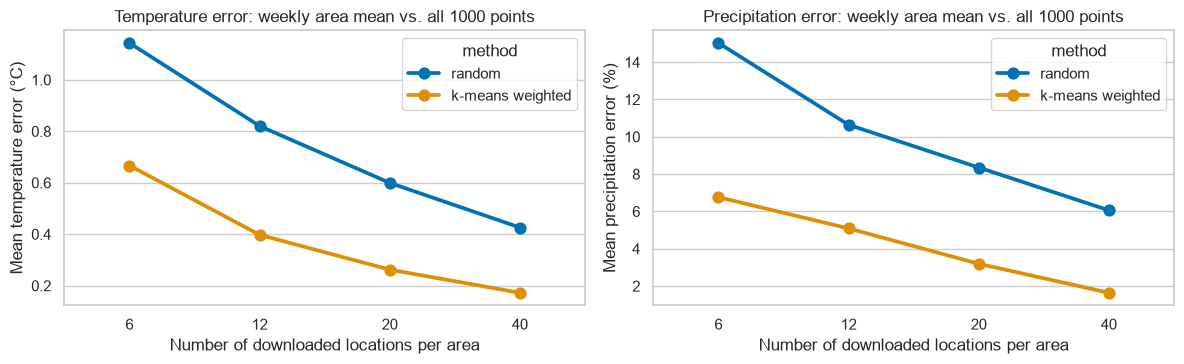

In [15]:
# Compare: weekly area means from n cells (random or k-means weighted) against the mean of all 1000 points
def cells_mean(weekly: pd.DataFrame, cells: pd.DataFrame, chosen: pd.DataFrame) -> pd.DataFrame:
    """Weighted weekly mean of the chosen cells (chosen has the columns lon, lat and weight)."""
    index = {(round(lon, 2), round(lat, 2)): i for i, (lon, lat) in enumerate(zip(cells['lon'], cells['lat']))}
    rows = [index[(round(lon, 2), round(lat, 2))] for lon, lat in zip(chosen['lon'], chosen['lat'])]
    weights = pd.Series(chosen['weight'].to_numpy() / chosen['weight'].sum(), index=rows)
    selected = weekly.loc[rows].reset_index()
    weighted = selected[['temperature', 'precipitation']].mul(selected['cell'].map(weights), axis=0)
    return weighted.groupby(selected['week']).sum()


rows = []
for (kind, number), (cells, weekly) in rep_data.items():
    truth = cells_mean(weekly, cells, cells.rename(columns={'points': 'weight'}))  # the mean of all 1000 points
    for n in [6, 12, 20, 40]:
        for seed in range(10):
            methods = {'random': cells.sample(n, random_state=seed).assign(weight=1.0),
                       'k-means weighted': representative_cells(area_points(points, kind, number), n, seed)}
            for method, chosen in methods.items():
                estimate = cells_mean(weekly, cells, chosen)
                error = estimate - truth
                rows.append({'method': method, 'locations': n, 'area': f'{kind} {number}',
                             'temperature error (°C)': error['temperature'].abs().mean(),
                             'precipitation error (%)': 100 * error['precipitation'].abs().sum()
                             / truth['precipitation'].sum()})
representativeness = pd.DataFrame(rows)
summary = representativeness.groupby(['locations', 'method'])[['temperature error (°C)',
                                                                'precipitation error (%)']].mean().unstack()
display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for axis, column in zip(axes, ['temperature error (°C)', 'precipitation error (%)']):
    sns.pointplot(representativeness, x='locations', y=column, hue='method', ax=axis, errorbar=None)
    axis.set(xlabel='Number of downloaded locations per area', ylabel=f'Mean {column}',
             title=column.split(' (')[0].capitalize() + ': weekly area mean vs. all 1000 points')
plt.tight_layout()
plt.show()

**Findings.** The k-means weighted cells have half the error of the same number of random cells or less, for every *n*. With 12 cells the weekly temperature is off by 0.40 °C on average (random: 0.82 °C) and the weekly
precipitation by 5 % (random: 11 %); 6 weighted cells already beat 12 random ones, and for precipitation even 20. The reason is the
weights: random cells count a sparsely sampled mountain cell as much as a cell that holds many of the points, while
each weighted cell stands for its share of the area. The first version of this notebook used 6 random cells (15 %
precipitation error) and Part 3 used 20 random cells (8 %); the new history uses 12 weighted cells (5 %), and the app's
hourly page 20 weighted cells (3 %) at the same cost as before. All 1000 points (100–500 distinct cells per area) are
not possible: ten years for one location cost about 280 calls, so about 600,000 calls against a free limit of 10,000
per day. 12 cells per area take about 27,000 calls, which were downloaded over three days. More cells would give
diminishing returns (40 cells: 1.6 %) for a much higher cost.

### 5.5 Store the weekly weather in MongoDB

In [16]:
# Upload: one document per area and week; a unique index and upserts make it safe to run the cell again
client = MongoClient(secrets['mongo']['uri'], serverSelectionTimeoutMS=10_000)
collection = client[secrets['mongo'].get('database', 'ind320')]['weather_weekly']
collection.create_index([('area_type', ASCENDING), ('area_number', ASCENDING), ('week', ASCENDING)], unique=True)
documents = weather_weekly.assign(area_number=weather_weekly['area_number'].astype(int)).round(3).to_dict('records')
result = collection.bulk_write([UpdateOne({k: doc[k] for k in ('area_type', 'area_number', 'week')},
                                          {'$set': doc}, upsert=True) for doc in documents])
print(f'inserted {result.upserted_count:,}, updated {result.modified_count:,}, unchanged '
      f'{len(documents) - result.upserted_count - result.modified_count:,}')
stored = collection.count_documents({})
assert stored == len(weather_weekly), 'MongoDB holds exactly one document per area and week'
print(f'{stored:,} documents in {collection.full_name}')

inserted 0, updated 5,094, unchanged 0
5,094 documents in ind320.weather_weekly


**Findings.** The table has 5,094 rows: 9 areas × 566 complete weeks from 10 January 2016 to 8 November 2026, the same weeks for
every area. Each value is the weighted mean of 12 representative ERA5 cells per area (section 5.4 tests how close this
is to the mean of all 1000 points). The areas differ as expected: the price area NO 2 (south-west) is the warmest
(5.2 °C) and NO 4 (north) the coldest (1.5 °C); the watercourse region VASS 2 (west) is the wettest (about 2,000 mm per
year), NO 1 (east) the driest (870 mm), and VASS 2 and NO 5 (west, with high mountains) get the most snow (about
300 cm per year). Norway as a whole (NO 0) has a mean of 3.3 °C and 1,280 mm per year. The upload uses upserts on a
unique index, so running the cell again never creates duplicates; in this run all 5,094 documents were updated,
because the first Part 4 version had stored values from 6 random cells per area.

## 6. Sliding window correlation: weather against reservoirs

The sliding window correlation (SWC) computes the correlation between two series in a window that moves along the time
axis. The weather series is shifted by a **lag**: with a positive lag, the reservoir in week *t* is compared with the
weather in week *t − lag*, so the weather comes first. As the representative reservoir variable I use the **weekly change
in fill level** (in percentage points), because inflow and outflow show up in the change, not in the level itself.
The same functions are used on the app page *Weather vs. reservoir* (`src/utils/analysis.py`).

In [17]:
# Functions: sliding window correlation at one lag, and the correlation over the whole period for every lag
def sliding_correlation(weather: pd.Series, reservoir: pd.Series, lag: int, window: int) -> pd.Series:
    """Correlation in a window of `window` weeks between the weather lag weeks earlier and the reservoir now."""
    pairs = pd.concat([weather.shift(lag), reservoir], axis=1).dropna()
    return pairs.iloc[:, 0].rolling(window, min_periods=int(0.8 * window)).corr(pairs.iloc[:, 1])


def lag_correlations(weather: pd.Series, reservoir: pd.Series, max_lag: int = 26) -> pd.Series:
    """Correlation over the whole period for each lag from -max_lag to +max_lag weeks."""
    return pd.Series({lag: weather.shift(lag).corr(reservoir) for lag in range(-max_lag, max_lag + 1)})


# Weekly change in fill level per area (percentage points), from the NVE data downloaded in section 4.
change = {(kind, int(number)): group.set_index('date')['endring_fyllingsgrad'].sort_index() * 100
          for (kind, number), group in nve.groupby(['omrType', 'omrnr'])}

NO 3: correlation at lag 0 = -0.33; strongest at lag 20 weeks = 0.47


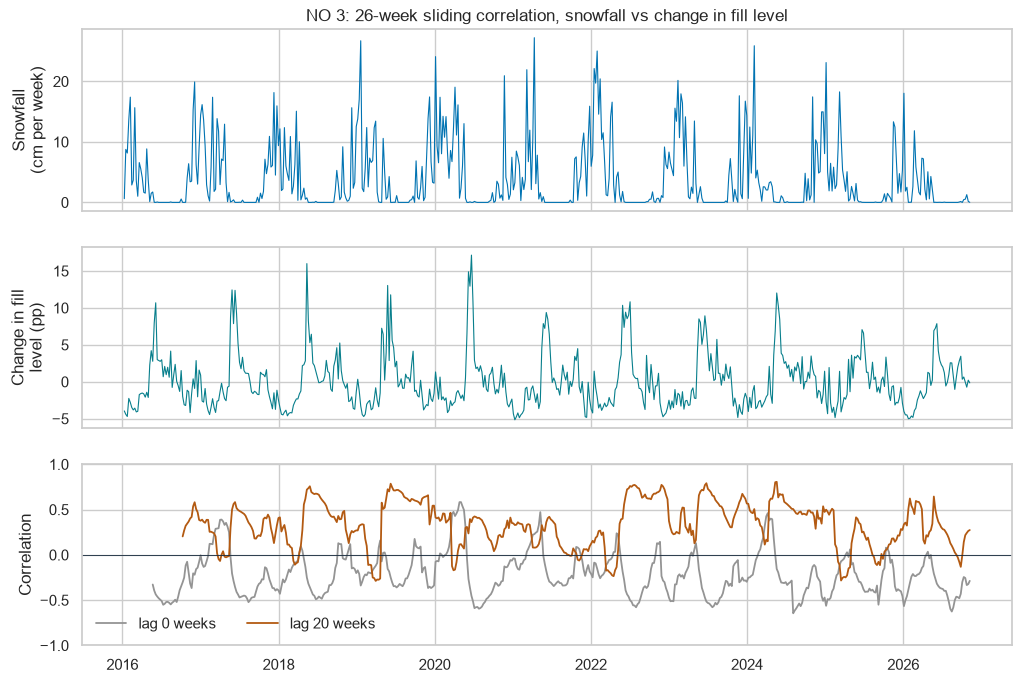

In [18]:
# Example: NO 3, snowfall against the weekly change, at lag 0 and at the lag with the strongest correlation
area, window = ('EL', 3), 26
snow = weekly_by_area[area]['snowfall']
reservoir = change[area].loc[snow.index[0]:snow.index[-1]]
by_lag = lag_correlations(snow, reservoir)
best_lag = int(by_lag.abs().idxmax())
print(f'NO 3: correlation at lag 0 = {by_lag[0]:.2f}; strongest at lag {best_lag} weeks = {by_lag[best_lag]:.2f}')

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(snow.index, snow, color='#0173B2', linewidth=0.8)
axes[0].set(ylabel='Snowfall\n(cm per week)', title=f'NO 3: {window}-week sliding correlation, snowfall vs change in fill level')
axes[1].plot(reservoir.index, reservoir, color='#087F8C', linewidth=0.8)
axes[1].set(ylabel='Change in fill\nlevel (pp)')
for lag, colour in [(0, '#949494'), (best_lag, '#B35A12')]:
    axes[2].plot(sliding_correlation(snow, reservoir, lag, window), color=colour, linewidth=1.3, label=f'lag {lag} weeks')
axes[2].axhline(0, color='#12263A', linewidth=0.6)
axes[2].set(ylabel='Correlation', ylim=(-1, 1))
axes[2].legend(frameon=False, ncol=2)
plt.show()

In [19]:
# Lag scan: strongest lag and correlation for every area and weather property (whole period, change in fill level)
rows = []
for area, frame in weekly_by_area.items():
    reservoir = change[area].loc[frame.index[0]:frame.index[-1]]
    for prop in ['temperature', 'precipitation', 'snowfall']:
        by_lag = lag_correlations(frame[prop], reservoir)
        best = int(by_lag.abs().idxmax())
        rows.append({'area': f'{area[0]} {area[1]}', 'property': prop, 'lag 0': by_lag[0],
                     'strongest lag (weeks)': best, 'correlation there': by_lag[best]})
lag_table = pd.DataFrame(rows).pivot(index='area', columns='property',
                                     values=['lag 0', 'strongest lag (weeks)', 'correlation there'])
display(lag_table.round(2))

lag 0                      strongest lag (weeks)           \
property precipitation snowfall temperature         precipitation snowfall   
area                                                                         
EL 1              0.29    -0.38        0.63                   0.0     21.0   
EL 2              0.28    -0.42        0.64                   0.0      2.0   
EL 3              0.23    -0.33        0.67                   0.0     20.0   
EL 4              0.29    -0.47        0.75                   0.0     23.0   
EL 5              0.26    -0.44        0.76                   0.0     23.0   
NO 0              0.29    -0.56        0.74                   0.0     21.0   
VASS 1            0.29    -0.44        0.68                   0.0     -1.0   
VASS 2            0.34    -0.31        0.72                   0.0     23.0   
VASS 3            0.24    -0.40        0.73                   0.0     23.0   

                     correlation there                       
property temperature     precipitation snowfall temperature  
area                                                         
EL 1             0.0              0.29     0.40        0.63  
EL 2             0.0              0.28    -0.44        0.64  
EL 3             0.0              0.23     0.47        0.67  
EL 4             0.0              0.29     0.54        0.75  
EL 5             0.0              0.26     0.53        0.76  
NO 0             0.0              0.29     0.59        0.74  
VASS 1           0.0              0.29    -0.45        0.68  
VASS 2           0.0              0.34     0.48        0.72  
VASS 3           0.0              0.24     0.51        0.73

**Findings.** At lag 0 the three weather properties behave differently in every area. **Temperature** has the strongest relation
(0.63–0.76): warm weeks are snowmelt and inflow weeks. **Precipitation** is weakly positive (0.23–0.34): rain becomes
inflow within the same week. **Snowfall** is negative (−0.31 to −0.56): snow falls in winter, when the reservoirs are
drawn down, and the water does not reach them yet. Shifting the snowfall by **20–23 weeks** turns the correlation
positive (0.40–0.59) in seven of the nine areas, so the snow of the winter shows up as inflow about five months later.
In NO 2 and VASS 1 the negative winter correlation is stronger than this delayed peak. The sliding windows show that
the relation is not constant: for NO 3 the 26-week correlation at lag 0 swings between about −0.6 and +0.6, depending
on whether the window covers the snow season or the melt, while at lag 20 it is positive in 86 % of the windows. This is why the
forecast below uses the weather as an input together with the time of year, and why the delayed effect of snow is a
candidate input (the "snowpack" variable sums the snowfall of the last 26 weeks).

## 7. Forecasting the fill level with River

**River** is a framework for online machine learning: a model learns from one observation at a time (`learn_one`)
and can keep learning when new data arrive. Two models are compared:

- **SNARIMAX** (`river.time_series.SNARIMAX`): seasonal ARIMA with exogenous variables. The orders *p, d, q* describe
  the recent weeks, the seasonal orders *sp, sd, sq* the same weeks in earlier years (season *m* = 52 weeks). The
  regression behind it is fitted online with stochastic gradient descent (SGD).
- **Lag regression**: a River linear regression (also SGD) that predicts **next week's change** in fill level from the
  current level, the last *p* changes, the change in the same week last year (*sp* = 1), the time of year (sine and
  cosine terms) and the chosen exogenous variables. The fill level is the running sum of the changes.

Both forecasts are **dynamic**: each forecast week is built on the forecasts of the weeks before it, not on observed
values. The future weather is unknown, so the forecast uses the **weekly climatology** (the mean of the same ISO week in
the training years); the exchange rate keeps its last value. For the **confidence band** (bonus task) two extra models
are trained with `optim.losses.Quantile` (the pinball loss), for example for the 10 % and 90 % quantiles. The pinball
loss has small, bounded gradients, so these two models use a ten times higher learning rate (section 7.7 shows why).

The function is in `src/utils/forecast.py`, so the app runs exactly the code tested here. Its inputs are the series,
the exogenous variables, the end of the training period and a `Settings` object with the model type, the orders, the
history length, the horizon, the learning rate, the number of epochs and the band width.

### 7.1 The forecasting function

In [20]:
# Show the main parts of the shared forecasting code: settings, lag features, future exogenous values and the function
for function in [fc.Settings, fc.lag_features, fc.future_exogenous, fc.forecast_fill]:
    print(inspect.getsource(function))

@dataclass(frozen=True)
class Settings:
    """All model settings. The defaults are the best settings from the notebook tests (section 7)."""
    model: str = "Lag regression"
    history_years: int = 8      # length of the training period (years of weeks)
    horizon: int = 26           # weeks to forecast
    p: int = 1                  # number of recent weekly changes (lag regression) / AR order (SNARIMAX)
    d: int = 0                  # SNARIMAX: differencing
    q: int = 0                  # SNARIMAX: moving-average order
    sp: int = 0                 # seasonal AR order (lag regression: use last year's change, 1 = yes)
    sd: int = 1                 # SNARIMAX: seasonal differencing
    sq: int = 0                 # SNARIMAX: seasonal moving-average order
    learning_rate: float = 0.001
    epochs: int = 5             # lag regression: passes over the training weeks
    interval: float = 0.8       # width of the confidence band (0.8 = 10 % and 90 % quantiles)

def lag_feat

### 7.2 Time resolution

NVE publishes one value per week, so the natural resolution is weekly. To check whether a finer or coarser resolution
would be better, the same SNARIMAX model (p = 1, sd = 1, five years of history, half a year ahead) is run on **daily**
values (the weekly fill level interpolated to days, season 365), **weekly** values (season 52) and **4-weekly** means
(season 13), from 10 forecast origins for Norway (NO 0). SGD needs a learning rate that suits the number of values, so
each resolution is run with three learning rates.

In [21]:
# Time resolution test: SNARIMAX on daily, weekly and 4-weekly fill level (NO 0, 10 origins, 5 years, half a year ahead)
fill = {(kind, int(number)): (group.set_index('date')['fyllingsgrad'].sort_index() * 100).asfreq('W-SUN').interpolate()
        for (kind, number), group in nve.groupby(['omrType', 'omrnr'])}
RESOLUTIONS = {'daily': ('D', 365, 182), 'weekly': ('W-SUN', 52, 26), '4-weekly': ('4W-SUN', 13, 7)}


def resolution_test(series: pd.Series, rule: str, season: int, horizon: int, origin: pd.Timestamp,
                    rate: float) -> tuple[float, float]:
    """Seconds to train and forecast, and the MAE (pp) of a SNARIMAX model at one resolution."""
    data = series.resample(rule).mean().interpolate() if rule != 'D' else series.resample('D').interpolate()
    train, test = data.loc[:origin].iloc[-5 * season:], data.loc[origin:].iloc[1:horizon + 1]
    model = time_series.SNARIMAX(p=1, d=0, q=0, m=season, sp=0, sd=1, sq=0, regressor=preprocessing.StandardScaler()
                                 | linear_model.LinearRegression(optimizer=optim.SGD(rate), intercept_lr=rate))
    start = time.perf_counter()
    for value in train:
        model.learn_one(value)
    prediction = np.array(model.forecast(horizon=horizon))[:len(test)]
    return time.perf_counter() - start, float(np.mean(np.abs(prediction - test.to_numpy())))


origins = pd.date_range('2021-01-03', '2025-08-31', freq='26W-SUN')
resolution_rows = []
for name, (rule, season, horizon) in RESOLUTIONS.items():
    for rate in [0.0003, 0.001, 0.003]:
        results = np.array([resolution_test(fill[('NO', 0)], rule, season, horizon, origin, rate) for origin in origins])
        resolution_rows.append({'resolution': name, 'learning rate': rate, 'training values': 5 * season,
                                'seconds per forecast': results[:, 0].mean(), 'MAE (pp)': results[:, 1].mean()})
resolution_table = pd.DataFrame(resolution_rows).set_index(['resolution', 'learning rate'])
# SGD can diverge (the error explodes) when the learning rate is too large for the data; show that as text.
resolution_table['MAE (pp)'] = resolution_table['MAE (pp)'].map(lambda v: f'{v:.2f}' if v < 1000 else 'diverged')
display(resolution_table.round(4))

training values  seconds per forecast  MAE (pp)
resolution learning rate                                                 
daily      0.0003                    1825                0.0036      9.21
           0.0010                    1825                0.0036  diverged
           0.0030                    1825                0.0036  diverged
weekly     0.0003                     260                0.0005      9.61
           0.0010                     260                0.0005      9.35
           0.0030                     260                0.0006      8.00
4-weekly   0.0003                      65                0.0002      9.94
           0.0010                      65                0.0002      9.85
           0.0030                      65                0.0002      9.56

**Findings.** **Weekly** resolution is the reasonable choice. Daily values give seven times as many training values (1,825 instead
of 260) and take about seven times as long, and the online SGD diverges unless the learning rate is lowered to 0.0003;
even then the error (9.2 pp) is no better than the weekly model (8.0 pp at learning rate 0.003). The daily values are
also only interpolated, because NVE measures once a week. 4-weekly means are the fastest, but with only 65 training
values the error is higher (9.6 pp). Every forecast takes only milliseconds at weekly resolution, so the tests below
can try many settings. The weather and the exchange rates are aggregated to the same weeks (sections 3 and 5).

### 7.3 Test design and baselines

Each setting is tested on **all 9 areas** (NO 0, EL 1–5, VASS 1–3) from **20 forecast origins** (every 13 weeks from
January 2021 to November 2025, so all seasons are included) with a **26-week horizon**. The error is the mean absolute
error (MAE) in percentage points (pp) over the 26 weeks, averaged over all 180 forecasts. Two simple baselines show what
a model must beat:

- **Persistence**: the fill level stays where it is.
- **Seasonal climatology**: the current level plus the mean change over the same weeks in the last five years.

In [22]:
# Test setup: areas, origins, the evaluation function and the two baselines
TEST_AREAS = [('NO', 0)] + [('EL', n) for n in range(1, 6)] + [('VASS', n) for n in range(1, 4)]
TEST_ORIGINS = pd.date_range('2021-01-03', '2025-11-02', freq='13W-SUN')
HORIZON = 26
print(len(TEST_AREAS), 'areas ×', len(TEST_ORIGINS), 'origins =', len(TEST_AREAS) * len(TEST_ORIGINS), 'forecasts per setting')


def evaluate(settings: fc.Settings, names: list[str] | None = None) -> dict:
    """Mean MAE (pp) over all test areas and origins, and the time per forecast, for one setting."""
    errors, start = [], time.perf_counter()
    for area in TEST_AREAS:
        exog = fc.build_exogenous(weekly_by_area[area], weekly_rates, names) if names else None
        for origin in TEST_ORIGINS:
            result = fc.forecast_fill(fill[area], exog, origin, settings, with_band=False)
            errors.append(fc.mean_absolute_error(result, fill[area]))
    return {'MAE (pp)': np.mean(errors), 'median MAE': np.median(errors),
            'seconds per forecast': (time.perf_counter() - start) / len(errors)}


def baseline_errors(area: tuple, origin: pd.Timestamp) -> tuple[float, float]:
    """MAE of persistence and of the seasonal climatology baseline for one area and origin."""
    series = fill[area]
    now, actual = series.loc[origin], series.loc[origin:].iloc[1:HORIZON + 1].to_numpy()
    past_changes = []
    for years_back in range(1, 6):  # the same 26 weeks in each of the last five years, as changes from their start
        start = series.index.get_loc(origin) - 52 * years_back
        past_changes.append(series.iloc[start + 1:start + 1 + HORIZON].to_numpy() - series.iloc[start])
    climatology = now + np.mean(past_changes, axis=0)
    return np.mean(np.abs(now - actual)), np.mean(np.abs(climatology - actual))


baselines = np.array([baseline_errors(area, origin) for area in TEST_AREAS for origin in TEST_ORIGINS])
print(f'Persistence: MAE {baselines[:, 0].mean():.2f} pp | Seasonal climatology: MAE {baselines[:, 1].mean():.2f} pp')

9 areas × 20 origins = 180 forecasts per setting
Persistence: MAE 19.38 pp | Seasonal climatology: MAE 7.33 pp


### 7.4 Lag regression: history length, learning rate and epochs

First without exogenous variables, with p = 2 recent changes and last year's change (sp = 1).

In [23]:
# Grid A: history length × learning rate × epochs for the lag regression (no exogenous variables)
grid_a = []
for years in [3, 5, 8]:
    for rate in [0.001, 0.003, 0.01]:
        for epochs in [1, 3, 5]:
            settings = fc.Settings(model='Lag regression', history_years=years, learning_rate=rate, epochs=epochs)
            grid_a.append({'history (years)': years, 'learning rate': rate, 'epochs': epochs, **evaluate(settings)})
grid_a = pd.DataFrame(grid_a).sort_values('MAE (pp)')
display(grid_a.head(8).round(3))
best_a = grid_a.iloc[0]

,history (years),learning rate,epochs,MAE (pp),median MAE,seconds per forecast
20,8,0.001,5,6.214,5.078,0.021
19,8,0.001,3,6.287,5.007,0.015
11,5,0.001,5,6.503,5.242,0.015
23,8,0.003,5,6.551,5.540,0.021
22,8,0.003,3,6.556,5.404,0.015
10,5,0.001,3,6.618,5.312,0.014
14,5,0.003,5,6.667,5.540,0.015
13,5,0.003,3,6.759,5.460,0.011


In [24]:
# Grid B: number of recent changes (p) and last year's change (sp) with the best values from grid A
grid_b = []
for p in [0, 1, 2, 4]:
    for sp in [0, 1]:
        settings = fc.Settings(model='Lag regression', history_years=int(best_a['history (years)']),
                               learning_rate=best_a['learning rate'], epochs=int(best_a['epochs']), p=p, sp=sp)
        grid_b.append({'p': p, 'sp': sp, **evaluate(settings)})
grid_b = pd.DataFrame(grid_b).sort_values('MAE (pp)')
display(grid_b.round(3))
best_b = grid_b.iloc[0]

,p,sp,MAE (pp),median MAE,seconds per forecast
2,1,0,6.214,5.078,0.021
3,1,1,6.260,5.091,0.022
5,2,1,6.267,5.269,0.023
4,2,0,6.276,5.215,0.022
7,4,1,6.303,5.342,0.026
6,4,0,6.337,5.439,0.024
0,0,0,6.482,5.088,0.020
1,0,1,6.751,5.586,0.021


### 7.5 SNARIMAX

In [25]:
# Grid C: a selection of SNARIMAX orders and learning rates (8 years of history, no exogenous variables)
grid_c = []
for p, d, q, sp, sd, sq in [(1, 0, 0, 0, 1, 0), (2, 0, 0, 0, 1, 0), (3, 0, 0, 0, 1, 0), (2, 1, 0, 1, 1, 0),
                            (1, 0, 1, 0, 1, 1), (2, 0, 1, 1, 1, 1)]:
    for rate in [0.001, 0.003]:
        settings = fc.Settings(model='SNARIMAX', history_years=8, p=p, d=d, q=q, sp=sp, sd=sd, sq=sq, learning_rate=rate)
        grid_c.append({'(p,d,q)(sp,sd,sq)': f'({p},{d},{q})({sp},{sd},{sq})', 'learning rate': rate, **evaluate(settings)})
grid_c = pd.DataFrame(grid_c).sort_values('MAE (pp)')
display(grid_c.round(3))

,"(p,d,q)(sp,sd,sq)",learning rate,MAE (pp),median MAE,seconds per forecast
3,"(2,0,0)(0,1,0)",0.003,7.614,6.650,0.007
5,"(3,0,0)(0,1,0)",0.003,8.027,6.762,0.006
4,"(3,0,0)(0,1,0)",0.001,8.074,7.135,0.007
11,"(2,0,1)(1,1,1)",0.003,8.321,7.121,0.007
1,"(1,0,0)(0,1,0)",0.003,8.593,6.785,0.006
7,"(2,1,0)(1,1,0)",0.003,8.701,7.140,0.007
6,"(2,1,0)(1,1,0)",0.001,8.872,7.687,0.006
2,"(2,0,0)(0,1,0)",0.001,9.632,7.641,0.007
10,"(2,0,1)(1,1,1)",0.001,9.673,9.062,0.007
9,"(1,0,1)(0,1,1)",0.003,9.822,8.259,0.006


### 7.6 Exogenous variables

The rows below use the best settings from grids A and B. The weekly weather starts in 2016, so with exogenous variables
the training cannot start earlier: for the first origins (2021–2023) the model gets five to seven years instead of eight.
The row without exogenous variables keeps its full history, so a weather variable must add more than the lost years
cost. This is the same choice the app faces.

In [26]:
# Grid D: exogenous variables with the best lag-regression settings (training starts in 2016 at the earliest with weather)
best_lag = fc.Settings(model='Lag regression', history_years=int(best_a['history (years)']),
                       learning_rate=best_a['learning rate'], epochs=int(best_a['epochs']),
                       p=int(best_b['p']), sp=int(best_b['sp']))
exogenous_sets = [[], ['temperature'], ['precipitation'], ['snowfall'], ['snowpack'], ['eur_nok'],
                  ['temperature', 'precipitation'], ['precipitation', 'snowfall'], ['snowpack', 'precipitation'],
                  ['snowpack', 'temperature'], ['temperature', 'precipitation', 'snowfall'],
                  ['precipitation', 'snowfall', 'eur_nok']]
grid_d = pd.DataFrame([{'exogenous variables': ', '.join(names) or '(none)', **evaluate(best_lag, names)}
                       for names in exogenous_sets]).sort_values('MAE (pp)')
display(grid_d.round(3))

,exogenous variables,MAE (pp),median MAE,seconds per forecast
7,"precipitation, snowfall",6.048,5.089,0.021
6,"temperature, precipitation",6.064,4.905,0.021
10,"temperature, precipitation, snowfall",6.070,4.910,0.022
2,precipitation,6.081,5.057,0.021
8,"snowpack, precipitation",6.098,5.073,0.022
3,snowfall,6.169,4.985,0.021
1,temperature,6.170,5.037,0.021
0,(none),6.214,5.078,0.021
4,snowpack,6.234,5.058,0.021
9,"snowpack, temperature",6.235,5.186,0.022


In a real forecast the weather of the coming weeks is unknown, and the climatology carries little news. To see how much
the weather *could* help, grid E repeats some rows with the **observed** weather in the forecast weeks (a perfect weather
forecast). This is only possible in a backtest, but it shows the value of the weather information itself.

In [27]:
# Grid E: climatology (real forecast) against the observed weather in the forecast weeks (perfect weather forecast)
def evaluate_observed(settings: fc.Settings, names: list[str]) -> float:
    """Mean MAE (pp) when the forecast weeks use the observed exogenous values (backtest only)."""
    errors = []
    for area in TEST_AREAS:
        exog = fc.build_exogenous(weekly_by_area[area], weekly_rates, names)
        for origin in TEST_ORIGINS:
            result = fc.forecast_fill(fill[area], exog, origin, settings, with_band=False, observed_future=True)
            errors.append(fc.mean_absolute_error(result, fill[area]))
    return float(np.mean(errors))


grid_e = pd.DataFrame([{'exogenous variables': ', '.join(names),
                        'MAE with climatology (pp)': evaluate(best_lag, names)['MAE (pp)'],
                        'MAE with observed weather (pp)': evaluate_observed(best_lag, names)}
                       for names in [['temperature'], ['precipitation'], ['temperature', 'precipitation'],
                                     ['precipitation', 'snowfall'], ['temperature', 'precipitation', 'snowfall']]])
display(grid_e.round(3))

,exogenous variables,MAE with climatology (pp),MAE with observed weather (pp)
0,temperature,6.170,5.818
1,precipitation,6.081,5.149
2,"temperature, precipitation",6.064,5.209
3,"precipitation, snowfall",6.048,5.009
4,"temperature, precipitation, snowfall",6.070,5.145


### 7.7 The default setting and its confidence band

The final check runs the app's default setting on all 180 test forecasts and counts how many observed weeks fall
inside the band. The first version of the band used the forecast's learning rate for the quantile models. They had not
converged after five epochs and crossed the forecast in about half of the weeks; the code then sorted the three values
per week, which silently changed the forecast itself (MAE 8.5 pp instead of 6.1 pp). Now the quantile models use a
ten times higher learning rate, and the band is only widened where a quantile model crosses the forecast, so the
forecast is never changed.

In [28]:
# Final check: the app's default setting, and how many observed weeks fall inside its band (all test forecasts)
def band_check(settings: fc.Settings, names: list[str]) -> dict:
    """MAE, share of observed weeks inside the band and mean band width over all test forecasts."""
    errors, inside, width = [], [], []
    for area in TEST_AREAS:
        exog = fc.build_exogenous(weekly_by_area[area], weekly_rates, names) if names else None
        for origin in TEST_ORIGINS:
            result = fc.forecast_fill(fill[area], exog, origin, settings, with_band=True)
            actual = fill[area].reindex(result.index)
            errors.append(fc.mean_absolute_error(result, fill[area]))
            inside.append(((actual >= result['lower']) & (actual <= result['upper'])).mean())
            width.append((result['upper'] - result['lower']).mean())
    return {'MAE (pp)': np.mean(errors), 'observed weeks inside the band': np.mean(inside),
            'mean band width (pp)': np.mean(width)}


default, default_exog = fc.Settings(), fc.DEFAULT_EXOGENOUS
print(default)
print('Exogenous variables:', default_exog, '| seasonal climatology baseline:', round(baselines[:, 1].mean(), 2), 'pp')
snarimax = fc.Settings(model='SNARIMAX', p=2, learning_rate=0.003)  # the best SNARIMAX from grid C
band_table = pd.DataFrame([
    {'model': 'Lag regression (default)', 'nominal band': '80 %', **band_check(default, default_exog)},
    {'model': 'Lag regression', 'nominal band': '50 %', **band_check(fc.with_settings(default, interval=0.5),
                                                                     default_exog)},
    {'model': 'SNARIMAX (2,0,0)(0,1,0), no weather', 'nominal band': '80 %', **band_check(snarimax, [])},
])
display(band_table.round(3))

Settings(model='Lag regression', history_years=8, horizon=26, p=1, d=0, q=0, sp=0, sd=1, sq=0, learning_rate=0.001, epochs=5, interval=0.8)
Exogenous variables: ['precipitation', 'snowfall'] | seasonal climatology baseline: 7.33 pp


,model,nominal band,MAE (pp),observed weeks inside the band,mean band width (pp)
0,Lag regression (default),80 %,6.048,0.930,40.685
1,Lag regression,50 %,6.048,0.800,24.329
2,"SNARIMAX (2,0,0)(0,1,0), no weather",80 %,7.614,0.623,20.575


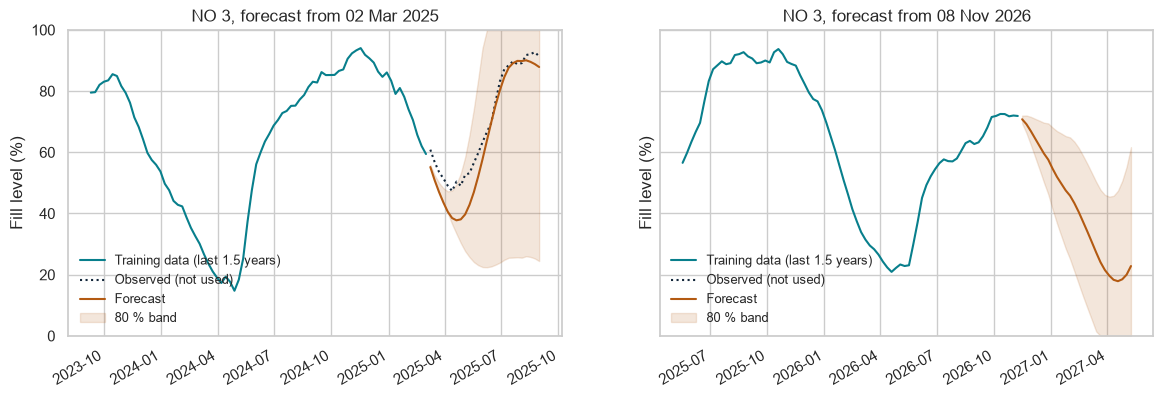

In [29]:
# Example: NO 3 forecast through the spring melt (from 2 March 2025) and from the newest week, with the 80 % band
area = ('EL', 3)
exog = fc.build_exogenous(weekly_by_area[area], weekly_rates, fc.DEFAULT_EXOGENOUS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for axis, origin in zip(axes, [pd.Timestamp('2025-03-02'), exog.index[-1]]):
    result = fc.forecast_fill(fill[area], exog, origin, fc.Settings(), with_band=True)
    history = fill[area].loc[:origin].iloc[-78:]
    axis.plot(history.index, history, color='#087F8C', label='Training data (last 1.5 years)')
    observed = fill[area].reindex(result.index).dropna()
    axis.plot(observed.index, observed, color='#12263A', linestyle=':', label='Observed (not used)')
    axis.plot(result.index, result['forecast'], color='#B35A12', label='Forecast')
    axis.fill_between(result.index, result['lower'], result['upper'], color='#B35A12', alpha=0.15, label='80 % band')
    axis.set(title=f'NO 3, forecast from {origin:%d %b %Y}', ylabel='Fill level (%)', ylim=(0, 100))
    axis.legend(frameon=False, fontsize=9, loc='lower left')
fig.autofmt_xdate()
plt.show()

**Findings and choice of defaults.** **Baselines.** Persistence is far off (19.4 pp), because the fill level has a strong seasonal cycle; the seasonal
climatology (7.3 pp) is the real baseline.

**Lag regression (grids A and B).** Eight years of history, learning rate 0.001 and five epochs are best (6.21 pp):
more history and more passes help, and a higher learning rate makes the SGD noisier. One recent change (p = 1) is
enough; last year's change (sp = 1) does not help, because the sine and cosine terms already describe the season.

**SNARIMAX (grid C).** The best order, (2,0,0)(0,1,0) with learning rate 0.003, reaches 7.61 pp and does not beat the
seasonal climatology; the moving-average terms and extra differencing make it worse, and it is sensitive to the
learning rate. SNARIMAX models the level (here its difference from the same week last year), while the lag regression
models the weekly change with the season as features, which suits a series that is mainly a yearly cycle.

**Exogenous variables (grids D and E).** Precipitation and snowfall together give the lowest error (6.05 pp, 3 % below
no weather): rain becomes inflow now, snow later, and the model needs both to tell them apart. Snowpack and
temperature hardly help, and the EUR/NOK rate makes the forecast worse (6.58 pp): it has no seasonal link to the fill
level, and the model probably learns a spurious relation to its trend. The small gain is expected, since the future
weeks only get the climatology. With the **observed** weather in the forecast weeks the error falls to 5.01 pp (17 %
lower). The weather matters, but the weather of the coming months is unknown; a real weather forecast covers only the
first one or two weeks.

**Defaults (used in the app).** Lag regression, 8 years of history, learning rate 0.001, 5 epochs, p = 1, sp = 0, with
precipitation and snowfall, 26 weeks ahead: 6.05 pp on the 180 test forecasts, 17 % better than the seasonal
climatology. One model takes about 0.02 s (three with the band), so the app can retrain on every change.

**Confidence band.** The 80 % band contains 93 % of the observed weeks and is wide (41 pp on average); the 50 % band
contains 80 %. The band is conservative because the weekly quantiles add up over 26 weeks, while real weeks do not all
end up at the same extreme. The SNARIMAX band contains only 62 %, so it is less reliable. The bug described above (the
sorting that changed the forecast) was found by this check: the default setting gave 8.5 pp here but 6.1 pp in grid D.

**Example.** From 2 March 2025 the NO 3 forecast has the right shape: the spring minimum and the melt, ending at 88 %
against the observed 91 %. The minimum is too low (38 % in April against 47 % observed). The forecast weeks only get
the climatology; with the observed weather of spring 2025 the minimum is almost right (47 %), although the error over
all 26 weeks of this single forecast is not lower; single forecasts vary, which is why the tests use 180 of them. From
the newest week (8 November 2026) the model expects NO 3 to fall to about 18 % in April 2027, with a wide band.

## 8. AI usage

I used Claude Code (Claude Opus) throughout Part 4. Claude wrote the majority of the code for the Streamlit pages, the
helper functions in `src/utils/`, and the code cells in the notebook. I also used Claude to investigate and formulate
findings for the peer review, and to draft the text in the notebook, including the explanations and findings in
sections 3–7 (currency data from Norges Bank, time zones, the weather history, the correlations and the forecasts).
Claude executed the downloading of weather data, updated the MongoDB database, ran the notebook, and exported the PDF.

I determined the application structure, hand-drew the layout based on a suggestion from Claude, approved the changes,
and tested the application myself. Following feedback from the instructor, I decided to incorporate the weighted method
for weather data. The results reported in the notebook are derived from the analyses performed.

## 9. Work log

I began Part 4 on November 15th by reviewing a fellow student's Part 3 submission. With assistance from Claude, I
examined the video frame by frame and identified an issue involving `pyarrow` and Python 3.14. I then wrote and
submitted the review myself. On my own Part 3 submission, I received feedback on four points: a CSV file in the
repository, the label "Robust std. dev." being cut off, many snowfall measurements being flagged as outliers, and that
the import statements should be placed in the first cell. All four were addressed in Part 4.

I drew a sketch of the application by hand. I adopted a menu structure grouped by task type. Claude implemented the menu, migrated the visualizations to Plotly,
and added pages for maps, the relationship between weather and reservoir levels, and reservoir level forecasts. I
personally tested the application. We resolved several issues, including Streamlit overriding the
figure theme and the thick outline of a clicked area on the map appearing only after the next click.

For the forecasting component, we experimented with both daily and weekly temporal resolutions. SNARIMAX proved
unstable when using daily data. While a lower learning rate provided some improvement, weekly resolution yielded
comparable results and was more computationally efficient. The lag-based regression model produced a forecast error of
6.2 percentage points, compared to 7.3 for the seasonal baseline and 7.6 for SNARIMAX. By incorporating precipitation
and snowfall data from the updated weather dataset, the error was reduced to 6.05 percentage points. When using
observed weather data, the error fell to approximately 5.0 percentage points, demonstrating the significant impact that
the quality of weather input can have on forecast accuracy.

Following feedback from the instructor on November 18, I wanted the regional averages to represent a larger number of
the 1,000 data points. The API quota made it impractical to retrieve the full historical dataset for every ERA5 grid
cell. Claude therefore tested a selection method based on k-means clustering, where each representative point was
weighted according to the number of points contained within its cluster. When compared against the full dataset, the
weekly precipitation error dropped from 15% (using six randomly selected points) to 5% (using twelve weighted points).
I decided to incorporate this method into the app. Claude re-downloaded the weather data, updated the
MongoDB database, and ran the notebook containing the new comparison.

I chose to include confidence intervals as the primary bonus task. During the final review, we discovered that the
sorting of the quantile limits could inadvertently alter the point forecast itself. Claude corrected this, ensuring the
point forecast remains unchanged while the confidence band expands as necessary. In testing, the 80% confidence band
encompassed 93% of the observed weeks. The app also covers the bonus tasks "Waiting time" and "Error handling": it
caches downloads and forecasts while providing feedback on current operations, and in the event of an API or database
error, the user is presented with an explanatory message.